In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import statsmodels.formula.api as smf

In [2]:
obs = pd.read_csv('data/55_Hare_Data_2012.txt')

In [3]:
obs.head()
obs.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3380 entries, 0 to 3379
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   date        3380 non-null   object 
 1   time        264 non-null    object 
 2   grid        3380 non-null   object 
 3   trap        3368 non-null   object 
 4   l_ear       3332 non-null   object 
 5   r_ear       3211 non-null   object 
 6   sex         3028 non-null   object 
 7   age         1269 non-null   object 
 8   weight      2845 non-null   float64
 9   hindft      1633 non-null   float64
 10  notes       243 non-null    object 
 11  b_key       3333 non-null   float64
 12  session_id  3380 non-null   int64  
 13  study       3217 non-null   object 
dtypes: float64(3), int64(1), object(10)
memory usage: 369.8+ KB


In [4]:
obs['date'] = pd.to_datetime(obs['date'])
print(obs['date'].dtype)

datetime64[ns]


In [6]:
obs['age'].value_counts(dropna=False)

age
NaN          2111
A             564
J             267
a             183
j             128
1/2/2013       21
1/4/2013       21
3/4/2013       18
1              12
U              11
?              10
a 3/4 yr.       4
2 yrs.          3
u               3
A 3/4           2
1.5             2
3.5 yrs.        2
2.25 yrs        2
1 yr.           2
1 yr            2
a 1 yr.         2
A 1.5           1
2.5 yrs         1
3 yrs.          1
a 2 yrs.        1
J 3/4           1
2 yrs           1
A 1/2           1
a 1 yr          1
1.25            1
3.25 yrs.       1
Name: count, dtype: int64

When you make a decison, document it. 
We will keep all hares with a j as juvenile, and all hares with a as an adult. 

In [7]:
#update age values to juvenile and adult for observations where 'a' and 'j' are included
obs.loc[obs['age'].str.contains('j', case=False, na=False), 'age'] = 'juvenile'
obs.loc[obs['age'].str.contains('a', case=False, na=False), 'age'] = 'adult'

#filter for confirmed observations of juvenile and adult hares
obs_juv_adult = obs[obs['age'].isin(['juvenile', 'adult'])].copy()
print('number of juvenile and adult hare observations (captures):', len(obs_juv_adult))

number of juvenile and adult hare observations (captures): 1155


In [8]:
obs_juv_adult['year'] = obs_juv_adult['date'].dt.year


In [9]:
obs_juv_adult.head()

,date,time,grid,trap,l_ear,r_ear,sex,age,weight,hindft,notes,b_key,session_id,study,year
108,1999-06-23,NaN,bonrip,2C,68,69,M,juvenile,395.0,126.0,NaN,643.0,53,Population,1999
109,1999-06-23,NaN,bonrip,2E,70,71,F,juvenile,420.0,137.0,NaN,653.0,53,Population,1999
110,1999-06-23,NaN,bonrip,3D,72,73,M,juvenile,445.0,144.0,NaN,944.0,53,Population,1999
111,1999-06-23,NaN,bonrip,4B,76,77,M,juvenile,410.0,115.0,NaN,663.0,53,Population,1999
112,1999-06-23,NaN,bonrip,4C,78,79,M,juvenile,430.0,132.0,NaN,670.0,53,Population,1999


In [12]:
# count observations per year and age, then move age values into columns
obs_per_year = obs_juv_adult.groupby(['year', 'age']).size().unstack()
obs_per_year

age,adult,juvenile
year,,
1999,150.0,126.0
2000,159.0,67.0
2001,72.0,22.0
2002,3.0,NaN
2003,1.0,18.0
2004,NaN,8.0
2005,95.0,48.0
2006,101.0,15.0
2007,13.0,5.0


In [13]:
obs_per_year.index

Index([1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010,
       2011, 2012],
      dtype='int32', name='year')

<Axes: title={'center': 'juvenile and adult snowshoe hare captures per year'}, xlabel='year', ylabel='number of captures'>

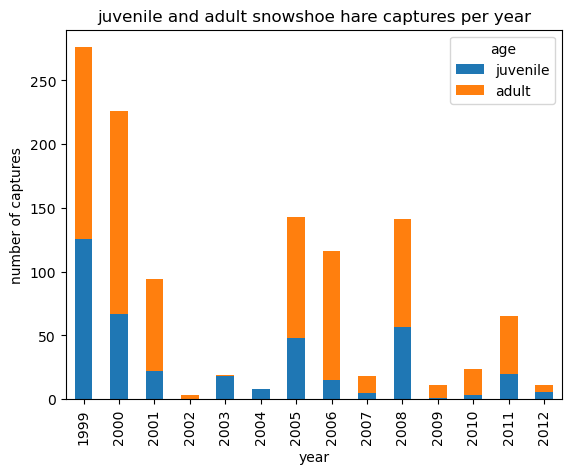

In [15]:
obs_per_year[['juvenile', 'adult']].plot(kind='bar', 
                                         stacked=True, 
                                         title='juvenile and adult snowshoe hare captures per year', 
                                         xlabel='year', 
                                         ylabel='number of captures')

Plotting with matplotlib

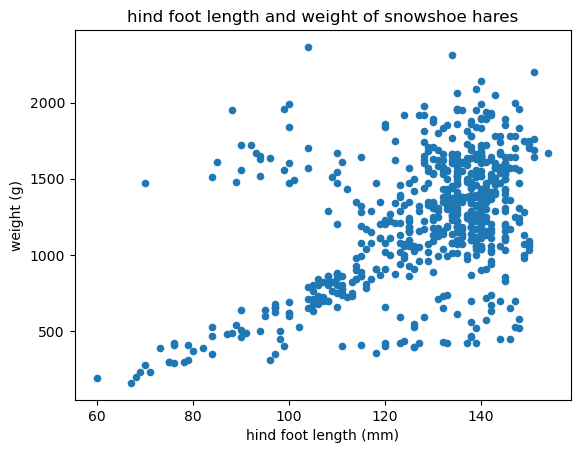

In [19]:
# initialise an empty figure (fig) and axes (ax)
fig, ax = plt.subplots()
#add scatter plot of hares data to our figures axes
obs_juv_adult.plot(kind='scatter', x = 'hindft', y='weight', ax=ax)
# update axes
ax.set_title('hind foot length and weight of snowshoe hares')
ax.set_xlabel('hind foot length (mm)')
ax.set_ylabel('weight (g)')
#display the plot
plt.show()

## Linear regression
for our analysis, we want to investigate possible relations between hind foot length and weight for juvenile hares


In [20]:
juv_w_hft = obs_juv_adult[obs_juv_adult['age']=='juvenile'].dropna(subset=['hindft', 'weight'])

number of observations 265


<Axes: xlabel='hindft', ylabel='weight'>

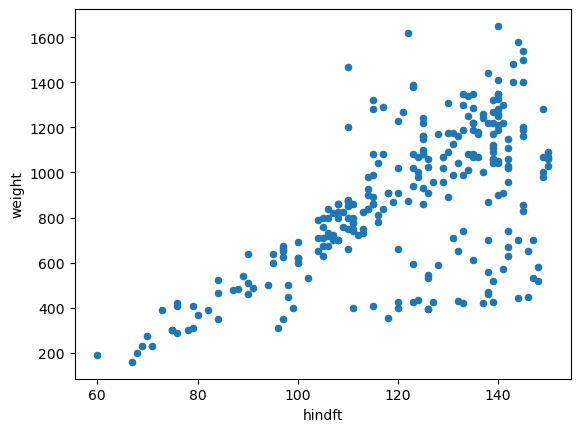

In [21]:
print('number of observations', len(juv_w_hft))
juv_w_hft.plot.scatter(x = 'hindft', y = 'weight')

In [23]:
# fit a model: weight explained by hind foot length
model = smf.ols('weight ~ hindft', data = juv_w_hft).fit()

In [24]:
model.params

Intercept   -352.771986
hindft        10.092240
dtype: float64

In [25]:
# retrieve parameters
intercept = model.params['Intercept']
print('y-intercept:', intercept)

slope = model.params['hindft']
print('slope:', slope)

y-intercept: -352.77198564640645
slope: 10.092239638623006


In [26]:
print('R^2:', model.rsquared)

R^2: 0.3871164783665738


R^2 is the coefficient of determination. It is betwen 0 and 1. R^2 = 1 is a perfect fit of the model to the data. We interpret it as the proportion of variance in the response that is explained by the least squares line with the predictor variable. 

In [28]:
# smallest and largest hind foot lengths
x_start = juv_w_hft['hindft'].min()
x_end = juv_w_hft['hindft'].max()

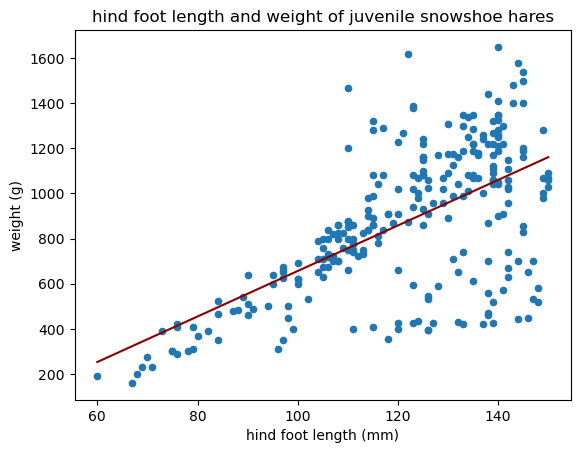

In [30]:
fig, ax = plt.subplots()
#add scatter plot of hares data to our figures axes
juv_w_hft.plot(kind='scatter', x = 'hindft', y='weight', ax=ax)
#add regression line to axes
ax.plot([x_start, x_end], 
        [intercept + slope * x_start, intercept + slope * x_end], color = 'darkred')
# update axes
ax.set_title('hind foot length and weight of juvenile snowshoe hares')
ax.set_xlabel('hind foot length (mm)')
ax.set_ylabel('weight (g)')
#display the plot
plt.show()

<Axes: title={'center': 'distribution of residuals'}, xlabel='residual (g)', ylabel='Frequency'>

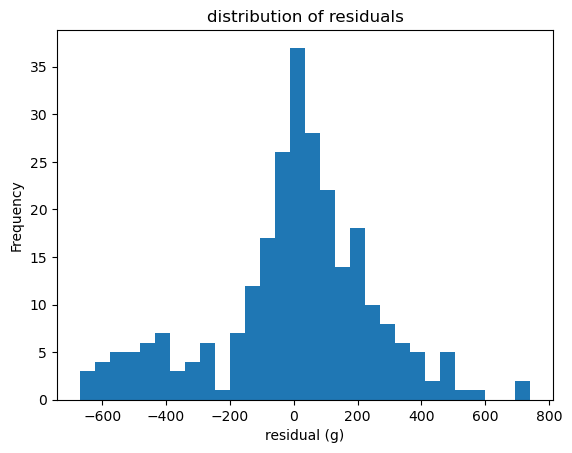

In [32]:
model.resid.plot(kind = 'hist', 
                 bins = 30, 
                 title = 'distribution of residuals', 
                 xlabel = 'residual (g)')

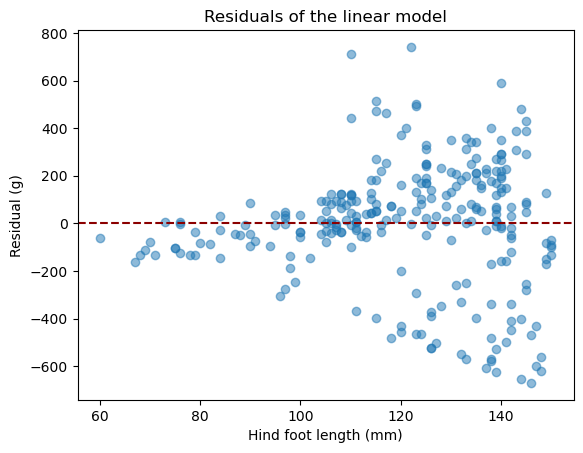

In [34]:
# Initialize empty figure and axes
fig, ax = plt.subplots()

# Add residuals to axes
ax.scatter(juv_w_hft['hindft'], model.resid, alpha=0.5)

# Add reference line at 0
ax.axhline(0, color='darkred', linestyle='--')

# Update axes
ax.set_title('Residuals of the linear model')
ax.set_xlabel('Hind foot length (mm)')
ax.set_ylabel('Residual (g)')

# Display figure
plt.show()